<a href="https://colab.research.google.com/github/DanDC25/Statistical-Learning-with-Python/blob/main/Practice_1_Linear_Regression_Diagnostics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practice 1: Diagnosing and Remedying Linear Model Failures

**Covers:** Weeks 2-4 (Linear Regression I-III)

**Due:** After completion of Lab 4

**Format:** Complete this notebook. Fill in every `### YOUR CODE HERE` cell and every ❓ Question cell with your written answer. Submit the rendered PDF alongside the `.ipynb`.

**AI tool policy:** AI coding assistants are permitted for coding only. Declare any use at the top of this notebook. All interpretations, modelling decisions, and written commentary must be your own.

**What you are being assessed on:** not whether you can run the code, but whether you can read the output and make a defensible modelling decision from it. Numbers without judgement earn no credit.

**Marks:** 2 marks x 20 items = 40 marks (10% of the overall grade). The 20 assessed items are the numbered Tasks and Questions below; they are listed in the checklist at the end.

***

## Part 0: Setup and Data

- Dataset: Concrete Compressive Strength (Yeh, 1998).
- Outcome `strength`, compressive strength in MPa.
- 8 predictors: quantities (kg per m³ mix) of `cement`, `slag`, `flyash`, `water`, `superplast` (superplasticizer), `coarse` and `fine` aggregate, plus `age` (days of curing).

This is a mixture-design dataset: the seven ingredient quantities are recorded per cubic metre of mix, so their total is close to constant from row to row, varying by only a few percent. Several predictors are therefore structurally related to one another. Keep that in mind for Part 2.

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import OLSInfluence, variance_inflation_factor
!pip install lmdiag
import lmdiag
from scipy import stats as scipy_stats
from statsmodels.graphics.regressionplots import plot_partregress_grid
# add more as needed
np.random.seed(2026)

In [29]:
url = "https://raw.githubusercontent.com/YBIFoundation/Dataset/main/Concrete%20Compressive%20Strength.csv"
concrete = pd.read_csv(url)
concrete.columns = ["cement", "slag", "flyash", "water", "superplast", "coarse", "fine", "age", "strength"]
concrete.index = range(1, len(concrete) + 1)

print(concrete.shape)
concrete.head()

(1030, 9)


,cement,slag,flyash,water,superplast,coarse,fine,age,strength
1,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
2,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
4,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
5,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


**Task 0.1 — Check for missing values.**

Confirm there are no missing values coded as NaN or as a placeholder (e.g. `"?"`). Report the result.

In [30]:
### YOUR CODE HERE
concrete.info()

print('The test for missing values found that all entries of this dataset are non-zero. Hence, there are no missing values.')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 1 to 1030
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   cement      1030 non-null   float64
 1   slag        1030 non-null   float64
 2   flyash      1030 non-null   float64
 3   water       1030 non-null   float64
 4   superplast  1030 non-null   float64
 5   coarse      1030 non-null   float64
 6   fine        1030 non-null   float64
 7   age         1030 non-null   int64  
 8   strength    1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB
The test for missing values found that all entries of this dataset are non-zero. Hence, there are no missing values.


***

## Part 1: Fit and Interpret

**Task 1.1 — Fit the full model.**

Fit a multiple linear regression of `strength` on all 8 predictors using `statsmodels`. Print the summary table.

In [31]:
### YOUR CODE HERE
# model = smf.ols(...).fit()
print(concrete.columns)

model = smf.ols('strength ~ cement + slag + flyash + water + superplast + coarse + fine + age', data=concrete).fit()
print(model.summary())
print(f'\nThe R^2 for this model is {model.rsquared.round(3)} and adjusted R^2 is {model.rsquared_adj.round(3)}')

Index(['cement', 'slag', 'flyash', 'water', 'superplast', 'coarse', 'fine',
       'age', 'strength'],
      dtype='object')
                            OLS Regression Results                            
Dep. Variable:               strength   R-squared:                       0.615
Model:                            OLS   Adj. R-squared:                  0.612
Method:                 Least Squares   F-statistic:                     204.3
Date:                Sun, 15 Nov 2026   Prob (F-statistic):          6.76e-206
Time:                        03:09:37   Log-Likelihood:                -3869.0
No. Observations:                1030   AIC:                             7756.
Df Residuals:                    1021   BIC:                             7800.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------

❓ **Question 1.1**
Report the R² and adjusted R². State in one sentence what proportion of variance in `strength` this model explains, and why you look at adjusted R² rather than R² alone when comparing models of different sizes.

*Your answer here:*

The proportion of total variance in strength that this model explains is R^2 which is 0.615; however, it appears that some predictors do not carry significant explanatory power of variance in strength which is penalized by adjust R^2, evidently by the decrease of 0.003 from 0.615 (R^2) to 0.612 (Adjust R^2).

The reason why I looked at adjusted R^2 and R^2 rather than R^2 alone when comparing models of different sizes because R^2 always increases as model size increase, which may be a biased  measurement as the inclusion of non-significant predictors that carry little to no explanatory power towards variance still increases R^2. Because adjusted R^2 penalizes the inclusion of predictors that do not carry sufficient explanatory power, it's a remedy to R^2's weakness. Hence, we should look at both measurements when comparing model of different sizes.

❓ **Question 1.2**
From the Task 1.1 summary, pick three predictors with different signs or magnitudes of effect. For each, state the coefficient, its unit, and a one-sentence ceteris paribus interpretation.

In [32]:
selected_predictors = ['flyash', 'water', 'superplast']
units = ['kg/m^3', 'kg/m^3', 'superplasticizer']
change = ['Increase by 0.087943 mPa', 'Decrease by 0.150298 mPa', 'Increase by 0.290687 mPa']

results = pd.DataFrame({
    'Coefficients': model.params[selected_predictors],
    'Units': units,
    'Change in strength': change

}, index=selected_predictors)
print(results)

            Coefficients             Units        Change in strength
flyash          0.087943            kg/m^3  Increase by 0.087943 mPa
water          -0.150298            kg/m^3  Decrease by 0.150298 mPa
superplast      0.290687  superplasticizer  Increase by 0.290687 mPa


*Your answer here:*

Flyash: for every unit increase of flyash (weight kg per volume m^3), strength of concrete increases by 0.087943 mPa


Water: for every unit increase of water (weight kg per volume m^3), strength of concrete decreases by 0.150298 mPa


Superplast: for every unit increase of superplast (superplasticizer), strength of concrete increases by 0.290687 mPa

**Task 1.3 — Confidence intervals.**

Extract the 95% confidence intervals for all coefficients using `.conf_int()`. Identify any predictor whose interval contains zero.

In [33]:
### YOUR CODE HERE

ci_95 = model.conf_int(alpha=0.05)
ci_95.columns = ['lower', 'upper']
ci_95.insert(0, 'estimate', model.params)
print('95% Confidence Intervals:')
print(ci_95.round(4))

95% Confidence Intervals:
            estimate    lower    upper
Intercept   -23.1638 -75.3380  29.0104
cement        0.1198   0.1031   0.1364
slag          0.1038   0.0840   0.1237
flyash        0.0879   0.0632   0.1126
water        -0.1503  -0.2291  -0.0715
superplast    0.2907   0.1073   0.4741
coarse        0.0180  -0.0004   0.0365
fine          0.0202  -0.0008   0.0412
age           0.1142   0.1036   0.1249


❓ **Question 1.3**
For the predictor(s) whose CI contains zero: does this mean the predictor has no relationship with `strength`? Explain what "contains zero" actually tells you, and what it does not tell you.

Predictors Coarse and Fine are found to contain 0 in the confidence interval. This does not suggest that that these predictors has no relationship with dependent variable strength.

Rather, it indicates that the coefficient is not stattistically significant at the 5% level; hence we cannot reject the null hypothesis.

This does not mean that the predictor has 0 relationship with strength. Perhaps it does have a marginal contribution to strength; however, perhaps there is strong multicollinearity between predictor Coarse, Fine, and other predictors that when accounted all together, other predictors "take back credit" as they share the same information.

**Task 1.4 — Overall and partial F-tests.**

1. Report the F-statistic and its p-value for the full model (already in the summary). State the null hypothesis being tested.
2. Fit a reduced model dropping two predictors you judge to be the weakest individual contributors. Run a partial F-test (`sm.stats.anova_lm`) comparing the reduced model against the full model.

In [34]:
concrete.columns

Index(['cement', 'slag', 'flyash', 'water', 'superplast', 'coarse', 'fine',
       'age', 'strength'],
      dtype='object')

In [35]:
### YOUR CODE HERE
# reduced_model = smf.ols(...).fit()
# sm.stats.anova_lm(reduced_model, model)

print('Null hypothesis is B(cement) = B(slag) = B(flyash) = B(water) = B(superplast) = B(coarse) = B(fine) = B(age) = 0')

# I choose to drop Coarse and Fine
reduced_model = smf.ols('strength ~ cement + slag + flyash + water + superplast + age', data=concrete).fit()
sm.stats.anova_lm(reduced_model, model)

Null hypothesis is B(cement) = B(slag) = B(flyash) = B(water) = B(superplast) = B(coarse) = B(fine) = B(age) = 0


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,1023.0,110855.967752,0.0,NaN,NaN,NaN
1,1021.0,110428.156817,2.0,427.810935,1.977734,0.138912


❓ **Question 1.4**
State the conclusion of the partial F-test in plain language. Does it support dropping the two predictors? Does this agree with what the individual t-tests on those two predictors already told you?

*Your answer here:*



The partial F-test concludes that dropping predictor Coarse and Fine is statistically significant in improving the model evidently by the F value and p-value. The F value is almost 1.977734 (almost double), and p-value is above the threshold of 0.05 being 0.138912, suggesting a statistically significant improvement from model to reduced_model. Hence, the conclusion of the partial F-test does support dropping the two predictors.

Moreover, the conclusion of the partial F-test does agree with the individual t-tests conlusion where the p-values of these two predictors are over the threshold of 0.05; respectively, p-values of Coarse and Fine are 0.055 and 0.060

***

## Part 2: Diagnose

Work with the full 8-predictor model from Part 1 for all diagnostics below.

**Task 2.1 — Four diagnostic plots.**

Produce: (a) residuals vs fitted, (b) normal Q-Q, (c) scale-location, (d) residuals vs leverage. You may build these manually with matplotlib or use `statsmodels` plotting utilities.

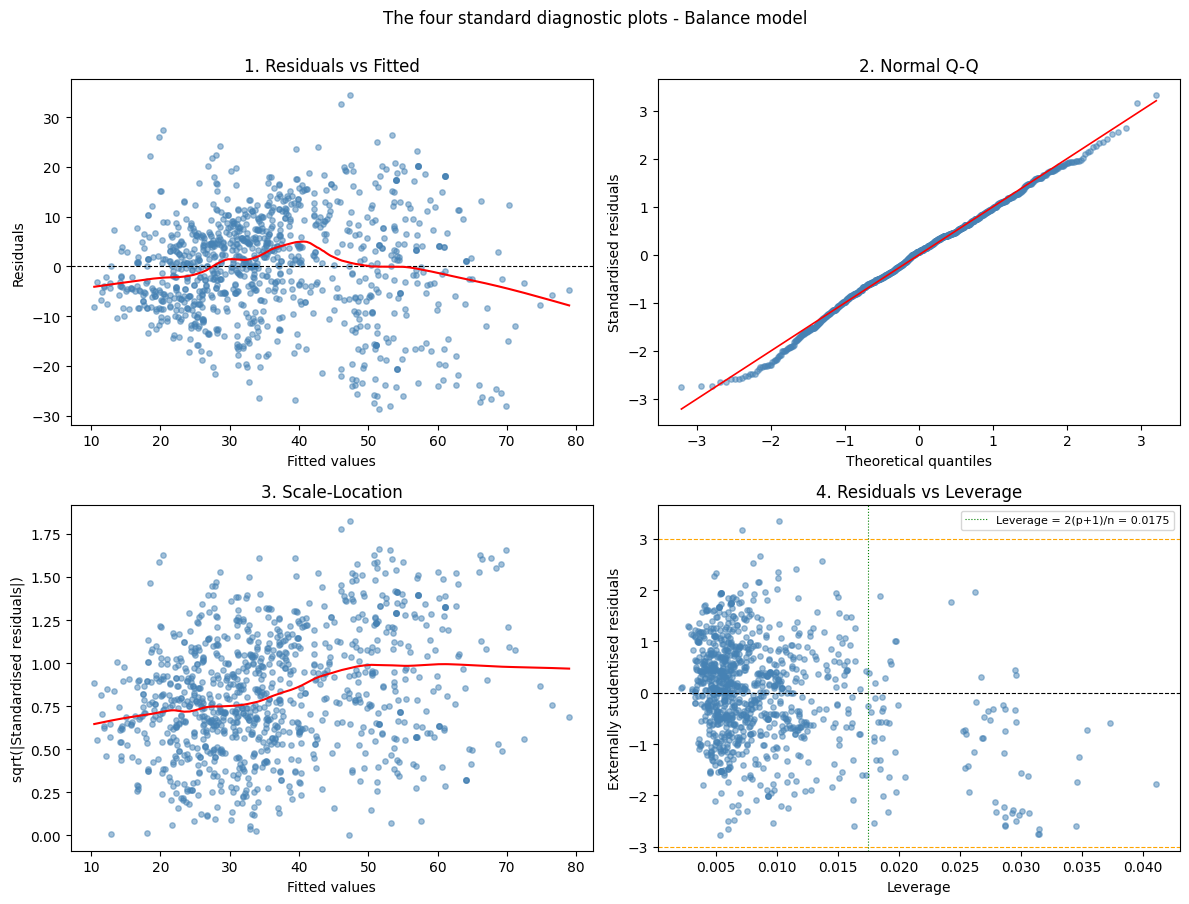

Largest |externally studentised residual|: 3.346
Observations above the leverage threshold: 80


In [36]:
### YOUR CODE HERE
fitted    = model.fittedvalues
residuals = model.resid
influence = OLSInfluence(model)
leverage        = pd.Series(influence.hat_matrix_diag,
                            index=concrete.index) # wrapped
std_resid       = influence.resid_studentized_internal   # internally studentised
studentised_ext = influence.resid_studentized_external   # externally studentised
cooks_d         = influence.cooks_distance[0]

n = model.nobs
p = model.df_model                 # number of predictors, excluding the intercept
lev_threshold = 2 * (p + 1) / n    # used again later


fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 1 - Residuals vs Fitted: linearity
ax = axes[0, 0] # position
ax.scatter(fitted, residuals, alpha=0.5, s=15, color='steelblue')
ax.axhline(0, color='black', lw=0.8, ls='--')
lo = sm.nonparametric.lowess(residuals, fitted, frac=0.3) # lowess
ax.plot(lo[:, 0], lo[:, 1], color='red', lw=1.5)
ax.set(xlabel="Fitted values", ylabel="Residuals", title="1. Residuals vs Fitted")

# 2 - Normal Q-Q: normality of the errors
ax = axes[0, 1]
(osm, osr), (slope, intercept, r) = scipy_stats.probplot(std_resid, dist="norm")
ax.scatter(osm, osr, alpha=0.5, s=15, color='steelblue')
ax.plot(osm, slope * np.array(osm) + intercept, color='red', lw=1.2)
ax.set(xlabel="Theoretical quantiles", ylabel="Standardised residuals", title="2. Normal Q-Q")

# 3 - Scale-Location: constant variance
ax = axes[1, 0]
sqrt_abs_resid = np.sqrt(np.abs(std_resid))
ax.scatter(fitted, sqrt_abs_resid, alpha=0.5, s=15, color='steelblue')
lo2 = sm.nonparametric.lowess(sqrt_abs_resid, fitted, frac=0.3)
ax.plot(lo2[:, 0], lo2[:, 1], color='red', lw=1.5)
ax.set(xlabel="Fitted values", ylabel="sqrt(|Standardised residuals|)",
       title="3. Scale-Location")

# 4 - Residuals vs Leverage: influence
ax = axes[1, 1]
ax.scatter(leverage, studentised_ext, alpha=0.5, s=15, color='steelblue')
ax.axhline(0, color='black', lw=0.8, ls='--')
for y in (3, -3):
    ax.axhline(y, color='orange', lw=0.8, ls='--')
ax.axvline(lev_threshold, color='green', lw=0.8, ls=':',
           label=f"Leverage = 2(p+1)/n = {lev_threshold:.4f}")
ax.legend(fontsize=8)
ax.set(xlabel="Leverage", ylabel="Externally studentised residuals",
       title="4. Residuals vs Leverage")

plt.suptitle("The four standard diagnostic plots - Balance model", y=1.00)
plt.tight_layout()
plt.show()

print(f"Largest |externally studentised residual|: {studentised_ext.abs().max():.3f}")
print(f"Observations above the leverage threshold: {(leverage > lev_threshold).sum()}")

❓ **Question 2.1**
For each of the four plots, state what you are checking for and whether the assumption holds. Be specific. Point to a feature of the plot (a curve, a fan shape, a departure from the line) that supports your conclusion.

*Your answer here:*

These four plots are named in the following order from top left to bottom right: Residual-Fitted, Q-Q, Scale location, and Residual vs Leverage, and are used to examine if a dataset satisfies the Gauss Markov's Theorem which is
- Linearity
- Homoscedasticity (constant variance)
- Exogeneity
- Uncorrelated errors



1. In residual-fitted we are checking for linearity in the dataset; moreover, the plot **may** also check for homoscedasticity, however, scale-location is the primary graph. It appears that the line residual-fitted plot isn't a U-shape, but rather, an almost linear horizontal line. Hence, I believe that the addition of a non-linear term isn't necessary that a usual U-Shape Residual vs Fitted plot suggests. Hence, the assumption of Linearity holds.

2. The Q-Q plot checks for any skewness in the data. Here, we can see that the dots follow the diagonal red line well. However, there appears to be a slight right skewness in the tails of the dataset; perhaps this is a very mild right-skewed dataset.

3. Scale-location plot checks for homoscedasticity; specifically, if the red line has an upward slope, it implies that variances increase with mean. Here in this plot, it appears that the red line is almost linear and horizontal; hence, there's sufficient evidence to believe that this dataset is homoscedastic as variances does not increase with mean.

4. Residual vs leverage plot check for influential observations, that is, observations that are high in leverage and also high in residuals. Leverage refers to how unusual the observation is in its predictor space whereas residual refers to the distance of observations to its predicted values. Here, we can see that many observations pass the leverage threshold by being on the right hand side of the drawn threshold line. More than that, some of these observations are also high in residual. Hence, we can conclude that some observations in this concrete dataset is influential and should be investigated first **not** automatic removal.


**Task 2.2 — Added variable plots.**

Construct AVPs for the predictors.

strength ~ cement + slag + flyash + water + superplast + coarse + fine + age


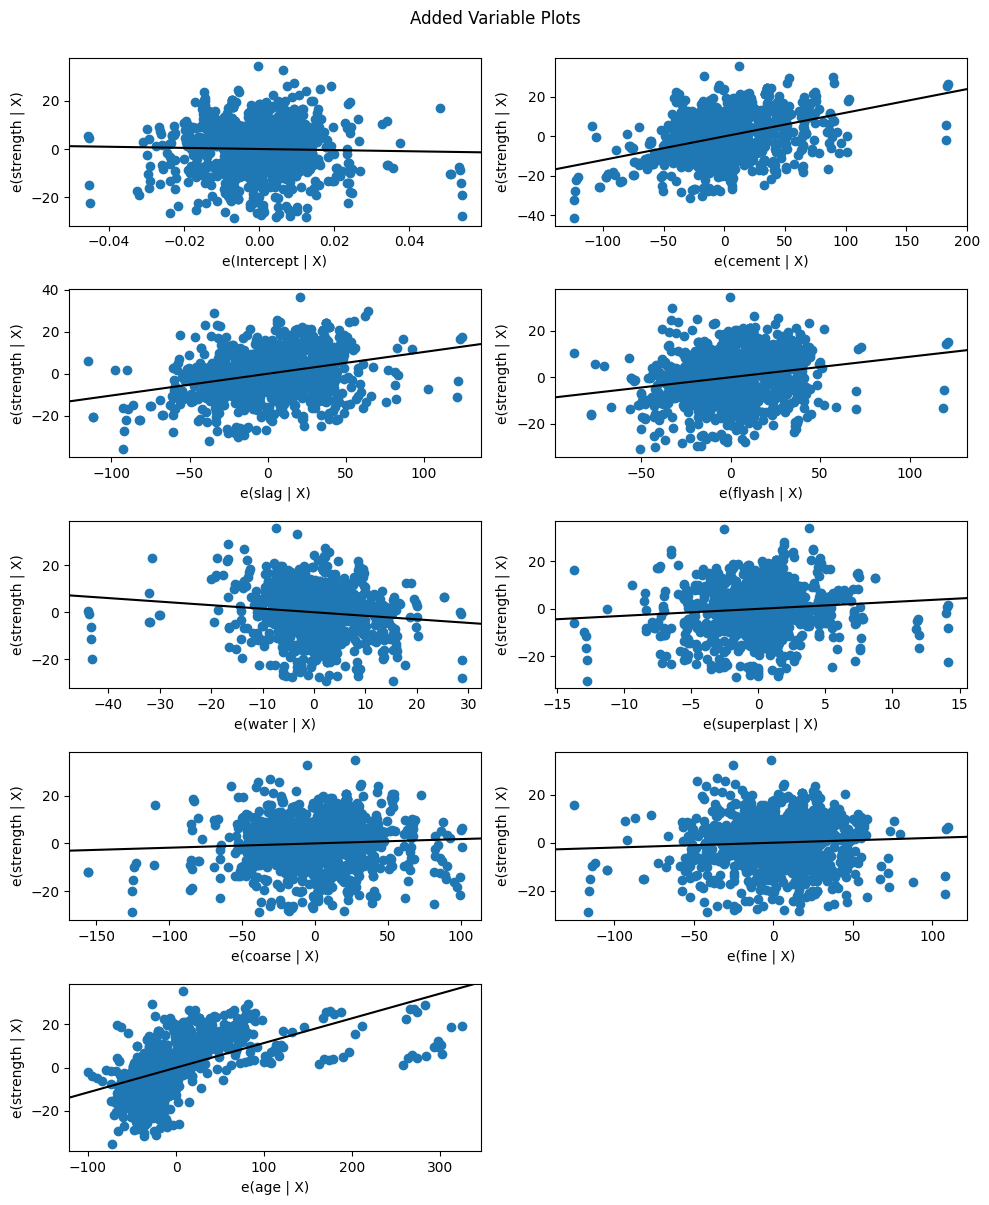

In [37]:
### YOUR CODE HERE
fig = plt.figure(figsize=(10, 12))
plot_partregress_grid(model, fig=fig)
fig.suptitle("Added Variable Plots", y=1.0)
print("strength ~ cement + slag + flyash + water + superplast + coarse + fine + age")
plt.tight_layout()
plt.show()

In [38]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:               strength   R-squared:                       0.615
Model:                            OLS   Adj. R-squared:                  0.612
Method:                 Least Squares   F-statistic:                     204.3
Date:                Sun, 15 Nov 2026   Prob (F-statistic):          6.76e-206
Time:                        03:09:54   Log-Likelihood:                -3869.0
No. Observations:                1030   AIC:                             7756.
Df Residuals:                    1021   BIC:                             7800.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -23.1638     26.588     -0.871      0.3

❓ **Question 2.2**
For your three predictors, does the AVP show a linear relationship, a nonlinear pattern, or effectively no relationship once the other predictors are accounted for? Does this match what the coefficient and its t-test suggested in Part 1?

For the three predictors that I selected, the AVP plot shows the following:

1. Flyash: there is a positive relationship between the predictor flyash and our dependent variable strength of concrete one other predictors are accounted for. This matches the coefficient-sign and p-value from t-tests from the summary table. Specifically, it matches the positive coefficient of 0.0879 and a p-value lower than the threshold (~ 0 < 0.05)

2. Water: there is a negative relationship between the predictor water and strength of concrete which matches the direction that its coefficient suggests -0.1503. Moreover, the independent t-test's suggestions also matches with the AVP - with a value of ~0 < 0.05, there is sufficient statistical evidence to suggest that there is a relationship between water and strength of concrete.

3. Superplast: the AVP plot shows a positive relationship between predictor superplast and strength of concrete, matching what the prediction's coefficient direction (and value) 0.2907. In addition, there appears to be a relationship, matching what its independent t-tests suggested with a p-value of 0.002 < 0.05. Hence, there is sufficient statistical evidence to suggest that there is a relationship between superplast and strength of concrete.

**Task 2.3 — Influence diagnostics.**

Compute leverage, studentised residuals, Cook's distance, and DFFITS for every observation (`OLSInfluence`). Flag observations exceeding the standard thresholds:
- Leverage > 2(p+1)/n
- Cook's D > 1 (or > 4/n as a softer flag)
- |DFFITS| > 2√((p+1)/n)

Produce an influence index plot and report how many observations each threshold flags, together with the largest value of each measure.

In [39]:
concrete.columns

Index(['cement', 'slag', 'flyash', 'water', 'superplast', 'coarse', 'fine',
       'age', 'strength'],
      dtype='object')

In [40]:
### YOUR CODE HERE

diag = concrete.copy()
diag["leverage"]  = leverage
diag["std_resid"] = studentised_ext
diag["cooks_d"]   = cooks_d
diag["dffits"]    = influence.dffits[0]      # .dffits returns (values, threshold)

# threholds
# leverage threshold computed above
cook_thresh_4n = 4 / n
dffits_thresh  = 2 * np.sqrt((p + 1) / n)

# Report red flags
print(f"n = {n:.0f},  p = {p:.0f},  mean leverage (p+1)/n = {(p + 1) / n:.4f}\n")
print(f"{'measure':10s} {'threshold':>10s} {'flagged':>8s}")
for col, thresh in [("leverage", lev_threshold), ("cooks_d", cook_thresh_4n),
                    ("dffits", dffits_thresh)]:
    print(f"{col:10s} {thresh:10.4f} {(diag[col].abs() > thresh).sum():8d}")

id_cols   = ['cement', 'slag', 'flyash', 'water', 'superplast', 'coarse', 'fine',
       'age', 'strength']
stat_cols = ["leverage", "std_resid", "cooks_d", "dffits"]
print(f"Leverage threshold: {cook_thresh_4n:.3f}")
print()
print("Top 10 by leverage:")
print(diag.nlargest(100, "cooks_d")[id_cols + stat_cols].round(4).to_string())

n = 1030,  p = 8,  mean leverage (p+1)/n = 0.0087

measure     threshold  flagged
leverage       0.0175       80
cooks_d        0.0039       79
dffits         0.1870       79
Leverage threshold: 0.004

Top 10 by leverage:
      cement    slag  flyash   water  superplast  coarse    fine  age  strength  leverage  std_resid  cooks_d  dffits
611   236.00    0.00    0.00  193.00        0.00   968.0  885.00  365   25.0831    0.0314    -2.7442   0.0270 -0.4945
57    475.00    0.00    0.00  228.00        0.00   932.0  594.00  365   41.9346    0.0314    -2.7443   0.0269 -0.4939
225   167.95   42.08  163.83  121.75        5.72  1058.7  780.11    3    7.7497    0.0345    -2.6005   0.0267 -0.4915
43    237.50  237.50    0.00  228.00        0.00   932.0  594.00  365   38.9954    0.0315    -2.6610   0.0254 -0.4797
4     332.50  142.50    0.00  228.00        0.00   932.0  594.00  365   41.0528    0.0287    -2.6036   0.0221 -0.4477
77    469.00  117.20    0.00  137.80       32.20   852.1  840.50    3 

❓ **Question 2.3**
Pick the two most influential flagged observations. For each: look up its predictor and outcome values, propose a reason it might be influential (data entry error, unusual case, boundary of predictor range, etc.), and state your decision (keep or investigate further) with justification. Compare the largest Cook's distance in the dataset against the conventional cut-off of 1 before you decide, and say what that comparison implies about deleting points from a sample this size. Do not delete an observation without this justification.

*Your answer here:*

The two most influential observations were found to be observation number 611 and 57. Both these observations are the two most influential observations, and they appear to share the same reasons:
1. Compared to other less influential observations, these two observations do not have any slag nor flyash. Other less observations tend to have at least slag or flyash, but it's uncommon to have neither.
2. Also compared to less influential observations, these observations do not have any superplast. Less influential observations have at least some superplast, it's uncommon to have 0.
3. Lastly, these 2 observations are older than other observations; they are aged and cured for 365 days, compared to less influential observations which are aged for less than 100 days.

However, comparing these values of the 2 observations, sometimes, less influential observations do possess these traits. Hence, I decide to keep these observations as I believe there may be other factors that affects their influence like data-entry error that is difficult to observe using the table above.

These observations are large relative to the threshold. To be specific, observation 611's Cook's Distance is 6.75 times the threshold whereas observation 57's Cook's Distance is 6.725 times the threshold. Granted, these observations do not cross the conventional cut-off of 1. Moreover, the threshold, itself, is a small value mostly because of the dataset's large size in nature. The threshold is calculated by 4/n; as n is a large number, the threshold becomes a small number. Hence, the observations' Cook's Distance relative to the threshold may be exaggerated due to a low base (low threshold).

**Task 2.4 — Collinearity.**

Compute VIF for every predictor and report them as a sorted table. Also print the correlation matrix of the 8 predictors.

In [41]:
### YOUR CODE HERE

X = model.model.exog # predictors
names = model.model.exog_names # predictor names

vif_df = pd.DataFrame({
    "Predictor": names,
    "VIF": [variance_inflation_factor(X, i) for i in range(X.shape[1])]
})
vif_df = vif_df[vif_df["Predictor"] != "Intercept"].reset_index(drop=True)
print(vif_df.sort_values("VIF", ascending=False).to_string(index=False))

corr = concrete.select_dtypes(include=np.number).corr() # compute correlation of numeric varaibles
corr.style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1).format("{:.3f}") # add colour

 Predictor      VIF
    cement 7.488657
      slag 7.276529
      fine 7.005346
     water 7.004663
    flyash 6.171455
    coarse 5.076044
superplast 2.965297
       age 1.118357


,cement,slag,flyash,water,superplast,coarse,fine,age,strength
cement,1.000,-0.275,-0.397,-0.082,0.093,-0.109,-0.223,0.082,0.498
slag,-0.275,1.000,-0.324,0.107,0.043,-0.284,-0.282,-0.044,0.135
flyash,-0.397,-0.324,1.000,-0.257,0.377,-0.010,0.079,-0.154,-0.106
water,-0.082,0.107,-0.257,1.000,-0.657,-0.182,-0.451,0.278,-0.290
superplast,0.093,0.043,0.377,-0.657,1.000,-0.266,0.223,-0.193,0.366
coarse,-0.109,-0.284,-0.010,-0.182,-0.266,1.000,-0.179,-0.003,-0.165
fine,-0.223,-0.282,0.079,-0.451,0.223,-0.179,1.000,-0.156,-0.167
age,0.082,-0.044,-0.154,0.278,-0.193,-0.003,-0.156,1.000,0.329
strength,0.498,0.135,-0.106,-0.290,0.366,-0.165,-0.167,0.329,1.000


❓ **Question 2.4**
List the predictors with VIF > 5, then check the correlation matrix and confirm that no single pairwise correlation is large enough to account for those values. Ingredient quantities are recorded per cubic metre, so their total is close to constant across rows: explain how a near-constant total produces inflation spread across most of the mix ingredients rather than concentrated in one pair. Finally, would dropping one ingredient fix it? State what you would do instead, and why.

*Your answer here:*

6 out of the total 8 predictors have VIF > 5. Predictors cement, slag, fine, water, flyash, and coarse respectively have VIFs of 7.488657, 7.276529, 7.005346, 7.004663, 6.171455, 5.076044.

However, when checking their correlation matrix, it appears that there are no single pair whose correlation is large enough to account for these large VIFs. The largest correlation among the pairs even exceed a magnitude of 0.500.

The large VIFs isn't due to correlations between predictors, evidently that it's low. It's because these predictors(ingredients) quantity sums close to a constant; when quantity of 1 predictor increase, quantity of another must decrease in order for the total to be close to a constant. Here, eventhough these predictors do not highly correlate, because they were bounded by a restriction to add up to a constant, their variances are inflated. Therefore, even if we drop one predictor/ingredient, the VIF would not significant improve as it isn't caused by a high-correlation problem in the first place.

Instead of restricting the ingredients to be added up to a constant, I would remove the restriction, and rather change the dependent variable into strength/volume(m^3). In doing so, the restriction is lifted, and each predictors do not "fight" each other to add up to any constant anymore. However, because a larger block of concrete is stronger than a smaller block of concrete, by changing the dependent variable into strength per unit of volume, we can measure the relative strength, and fixes the problem of high VIF.


***

## Part 3: Remedy and Re-evaluate

❓ **Question 3.1**
Choose **one** failure from Part 2 to fix. Two candidates are live in this dataset: the nonlinear effect of `age` on `strength` flagged in its AVP (Task 2.2), and the mixture collinearity in the VIF table (Task 2.4). State which one you are addressing and why you chose it over the other.

Removing an influential observation is deliberately not on that list. Using your Task 2.3 output, state in one sentence why it would not be a useful remedy here. Do not take that on trust.

*Your answer here:*

I am addressing the failure of the non-linear effect of age on strength in task 2.2 over task 2.4 because mixture collinearity in the VIF table isn't solely caused by correlation, but by the mixture-restriction in nature which requires a more significant remedy compared to adding a non-linear term in task 2.2's failure.

Therefore, to fix Task 2.2's problem - the non-linear effect of age on strength, age's parameter will become a non-linear term.

**Task 3.2 — Implement the remedy.**

Apply it: a transformation of the offending predictor, or a re-specification of the collinear ingredients. Dropping a variable is not the only option for collinearity. A ratio or a composite of two ingredients may serve better, and concrete engineering has a conventional one. Refit the model.

In [49]:
### YOUR CODE HERE
# remedied_model = smf.ols(...).fit()
remedied_model = smf.ols('strength ~ cement + slag + flyash + water + superplast + coarse + fine + np.log(age)', data=concrete).fit()



**Task 3.3 — Re-run diagnostics and compare.**

Repeat the diagnostic that flagged the failure (not necessarily all four) on the remedied model, then build a short table comparing the original and remedied model: R², adjusted R², and the specific diagnostic you targeted (e.g. max VIF, or the AVP shape for `age`).

strength ~ cement + slag + flyash + water + superplast + coarse + fine + age


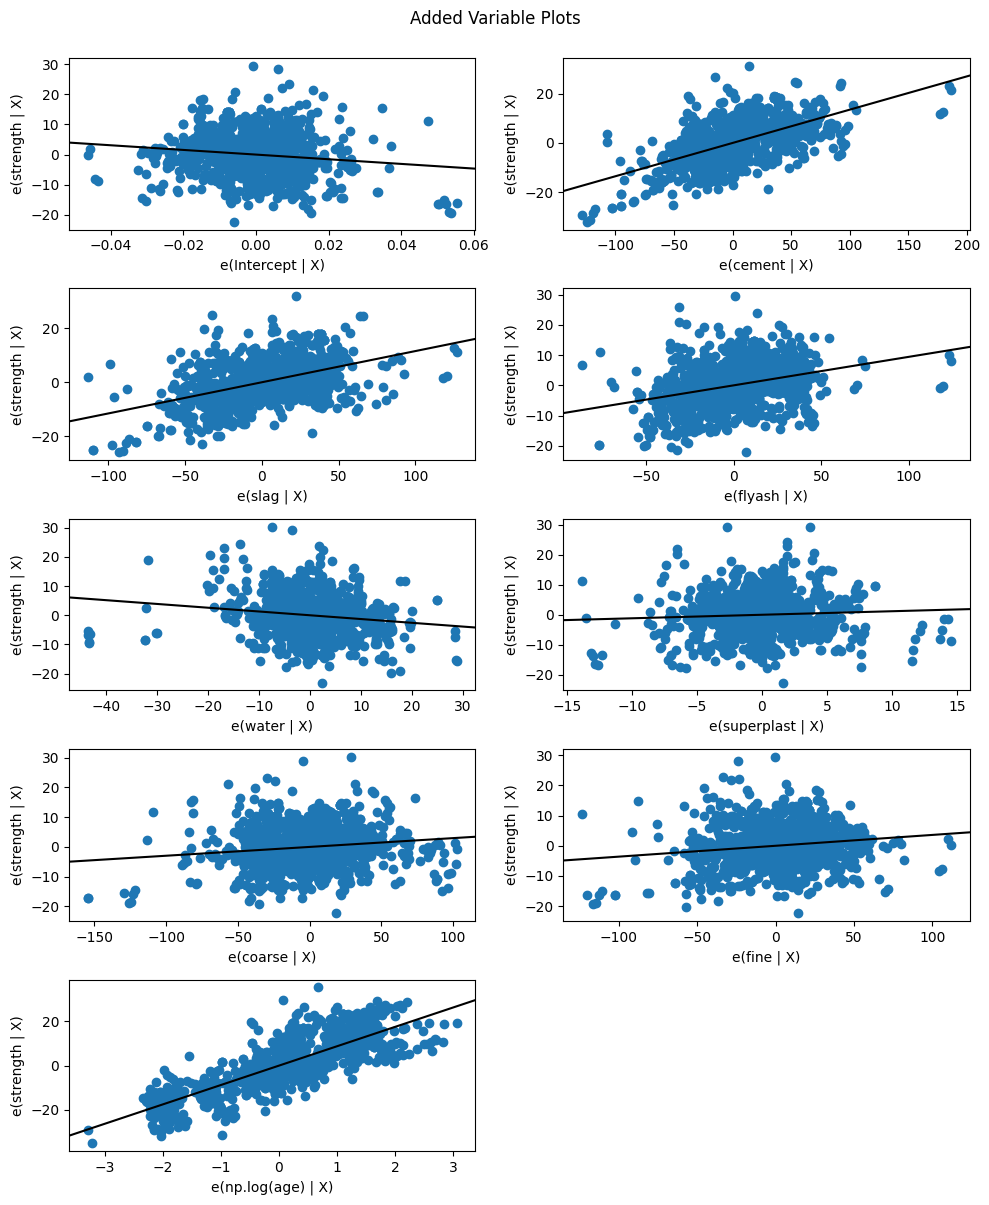

                          R^2  Adjusted R^2 Shape of AVP
Original Full Model  0.615465      0.612452       Linear
Remedied Model       0.818483      0.817061   Non-linear


In [65]:
### YOUR CODE HERE
# 1. Re-run the diagnostic(s) relevant to the failure you fixed
# 2. Build the before/after comparison table
### YOUR CODE HERE
fig = plt.figure(figsize=(10, 12))
plot_partregress_grid(remedied_model, fig=fig)
fig.suptitle("Added Variable Plots", y=1.0)
print("strength ~ cement + slag + flyash + water + superplast + coarse + fine + age")
plt.tight_layout()
plt.show()


diagnostic_results = pd.DataFrame({
    'R^2': [model.rsquared, remedied_model.rsquared],
    'Adjusted R^2': [model.rsquared_adj, remedied_model.rsquared_adj],
    'Shape of AVP': ['Linear', 'Non-linear']
}, index=['Original Full Model', 'Remedied Model'])

print(diagnostic_results)



❓ **Question 3.3 — Final reflection**
Did the remedy fix the problem it targeted? Did it introduce or worsen any other diagnostic issue. Check at least one other diagnostic on the remedied model. Would you deploy the remedied model over the original? State your answer and your reason in two sentences.

*Your answer here:*

Yes, the the remedy did fix the problem it targeted; specifically, the shape of the AVP curve originally did not match the shape of the non-linear observations. Now, after the log transformation of predictor "age", its AVP curve shape does match the shape of the observations.

Moreover, the increase in R^2 (from 0.615465 to 0.818483) and adjusted R^2 (from 0.612452 to 0.817061) reinforces the claim that the remedied model performs better than the original model. Evidently, the predictor "age" is log-transformed, both R^2 and adjusted R^2 increases respectively by 0.203018 and 0.204609.

Hence, I would deply the remedied model over the original as there is sufficient evidence to believe that the remedied model performs better than original model. Specifically, as both R^2 and adjusted R^2 improves once the predictor "age" is log-transformed in the remedied model.


***

## Submission Checklist

- [ ] AI tool use declared (if applicable)
- [ ] Missing-value check reported (Task 0.1)
- [ ] Full model fitted, R² and coefficients interpreted (Task 1.1, Questions 1.1-1.2)
- [ ] Confidence intervals extracted and discussed (Task 1.3, Question 1.3)
- [ ] Overall and partial F-tests run and concluded (Task 1.4, Question 1.4)
- [ ] All four diagnostic plots produced and discussed (Task 2.1, Question 2.1)
- [ ] AVPs for at least three predictors including `age` (Task 2.2, Question 2.2)
- [ ] Influence diagnostics computed, flagged points adjudicated with reasons (Task 2.3, Question 2.3)
- [ ] VIF and correlations computed, mixture collinearity explained (Task 2.4, Question 2.4)
- [ ] Failure chosen and justified (Question 3.1), remedy implemented (Task 3.2)
- [ ] Diagnostics re-run and before/after table built (Task 3.3)
- [ ] Final reflection answered (Question 3.3)
- [ ] Notebook rendered to PDF via Quarto and submitted alongside the `.ipynb`

**The 20 assessed items, 2 marks each:** Task 0.1 | Tasks 1.1, 1.3, 1.4 and Questions 1.1, 1.2, 1.3, 1.4 | Tasks 2.1, 2.2, 2.3, 2.4 and Questions 2.1, 2.2, 2.3, 2.4 | Question 3.1, Task 3.2, Task 3.3, Question 3.3